# RappiPlus | Business Performance Analysis

## 1. Project Overview

### Objective

Evaluate RappiPlus business performance from January to June 2025, focusing on revenue, product profitability, customer behavior, and marketing efficiency.

### Analytical Scope

- Revenue trends and commercial performance.
- Product and category profitability.
- Customer purchasing behavior.
- Geographic and acquisition channel performance.
- Marketing investment efficiency.

### Data Sources

This analysis uses the cleaned datasets generated during the data preparation phase.

Data quality limitations and analytical exclusions are documented in the previous notebooks.

In [16]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# Load cleaned datasets

orders = pd.read_csv(
    '../data/processed/rappiplus_orders_clean.csv',
    parse_dates=['fecha_hora_pedido']
)

marketing = pd.read_csv(
    '../data/processed/rappiplus_marketing_clean.csv',
    parse_dates=['fecha']
)

catalog = pd.read_csv(
    '../data/processed/rappiplus_catalog_clean.csv'
)

print('Orders:', orders.shape)
print('Marketing:', marketing.shape)
print('Catalog:', catalog.shape)

Orders: (24990, 17)
Marketing: (1620, 5)
Catalog: (7, 4)


## 2. Revenue Analysis

### Business Question

How did RappiPlus revenue evolve from January to June 2025?

### Methodology

Revenue will be analyzed using the cleaned orders dataset, excluding the ten extreme-quantity transactions identified during data preparation.

Positive sales, potential returns, and transactions with unknown quantities will be distinguished to avoid misleading financial conclusions.

In [18]:
# Calculate monthly recorded amounts by transaction type

orders['mes'] = orders['fecha_hora_pedido'].dt.to_period('M')

monthly_revenue = (
    orders.groupby(['mes', 'tipo_transaccion'])['monto_total']
    .sum()
    .unstack(fill_value=0)
)

monthly_revenue['total_registrado'] = monthly_revenue.sum(axis=1)

monthly_revenue.round(2)

tipo_transaccion,Possible return,Sale,Unknown,total_registrado
mes,,,,
2025-01,0.00,1656274.48,3095.64,1659370.12
2025-02,-492.65,1442435.17,2166.85,1444109.37
2025-03,-192.62,1657916.75,5268.96,1662993.09
2025-04,0.00,1599342.28,3458.99,1602801.27
2025-05,-462.03,1650821.10,4342.27,1654701.34
2025-06,0.00,1615491.78,3295.29,1618787.07


In [19]:
# Calculate month-over-month sales growth

monthly_revenue['sales_growth_pct'] = (
    monthly_revenue['Sale'].pct_change() * 100
)

monthly_revenue[
    ['Sale', 'sales_growth_pct']
].round(2)

tipo_transaccion,Sale,sales_growth_pct
mes,,
2025-01,1656274.48,NaN
2025-02,1442435.17,-12.91
2025-03,1657916.75,14.94
2025-04,1599342.28,-3.53
2025-05,1650821.10,3.22
2025-06,1615491.78,-2.14


In [20]:
# Calculate overall sales growth

first_month = monthly_revenue['Sale'].iloc[0]
last_month = monthly_revenue['Sale'].iloc[-1]

overall_growth = (last_month / first_month - 1) * 100

print('January sales:', round(first_month, 2))
print('June sales:', round(last_month, 2))
print('January-to-June growth (%):', round(overall_growth, 2))

January sales: 1656274.48
June sales: 1615491.78
January-to-June growth (%): -2.46


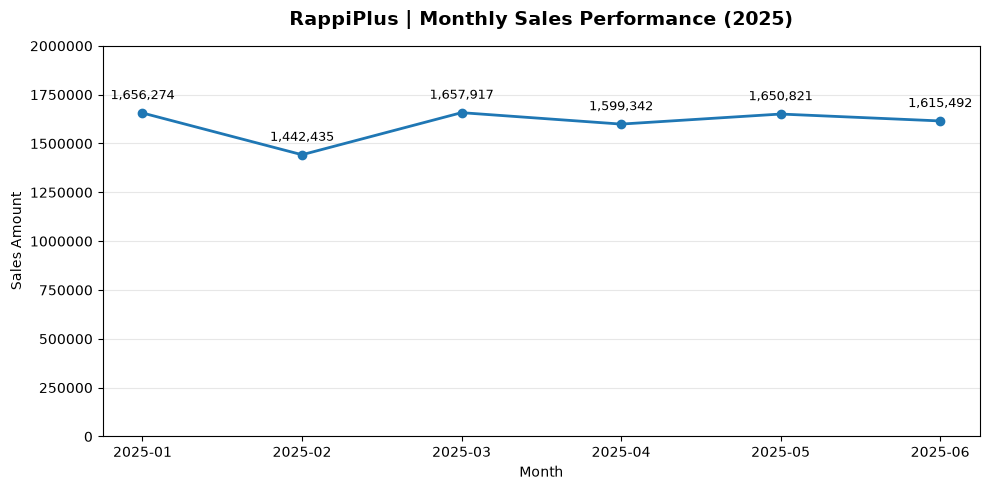

In [21]:
# Visualize monthly sales performance

months = monthly_revenue.index.astype(str)
sales = monthly_revenue['Sale'].values

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    months,
    sales,
    marker='o',
    linewidth=2
)

ax.set_title(
    'RappiPlus | Monthly Sales Performance (2025)',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Month')
ax.set_ylabel('Sales Amount')

ax.grid(axis='y', alpha=0.3)

ax.ticklabel_format(
    axis='y',
    style='plain',
    useOffset=False
)

ax.set_ylim(0, 2000000)

for month, sale in zip(months, sales):
    ax.annotate(
        f'{sale:,.0f}',
        (month, sale),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()

### Key Finding: Revenue Performance

RappiPlus showed fluctuating monthly sales during the first half of 2025, without sustained growth.

- Sales decreased by 2.46% between January and June.
- February recorded the largest monthly decline (-12.91%).
- March showed the strongest recovery (+14.94%).

The results indicate an absence of consistent sales growth during the analyzed period.

Further analysis is needed to determine whether these fluctuations are driven by changes in order volume, customer behavior, or product performance.

## 3. Product Profitability Analysis

### Business Question

Which products contribute the most to RappiPlus profitability, and which products generate financial losses?

### Methodology

Product profitability is evaluated using transactions with positive quantities and available product costs.

Revenue, estimated product costs, gross profit, and gross margin are calculated for each product.

Transactions with missing cost information and potential returns are excluded from profitability calculations.

In [22]:
# Analyze product profitability

profitable_orders = orders[
    orders['profit_eligible'] == True
].copy()

product_profitability = (
    profitable_orders.groupby('nombre_producto')
    .agg(
        orders=('id_pedido', 'count'),
        revenue=('monto_total', 'sum'),
        product_cost=('costo_total', 'sum'),
        gross_profit=('utilidad_bruta', 'sum')
    )
    .reset_index()
)

# Calculate gross margin
product_profitability['gross_margin_pct'] = (
    product_profitability['gross_profit']
    / product_profitability['revenue'] * 100
)

# Sort by profitability
product_profitability = product_profitability.sort_values(
    'gross_profit',
    ascending=False
)

product_profitability.round(2)

,nombre_producto,orders,revenue,product_cost,gross_profit,gross_margin_pct
6,Vacuum-Pro-Black,4170,1621051.85,104314.40,1516737.45,93.57
4,Sneakers-Urban-42,4129,1566075.93,106220.12,1459855.81,93.22
3,Phone-Pro-128GB,2733,1057134.62,41896.80,1015237.82,96.04
5,Tablet-Standard-64GB,2764,1062922.80,104697.13,958225.67,90.15
0,Blender-XL-Red,4176,1611574.59,1109122.56,502452.03,31.18
1,Jacket-Winter-M,4166,1606586.17,1184323.36,422262.81,26.28
2,Laptop-Gaming-16GB,2768,1084672.98,1178294.64,-93621.66,-8.63


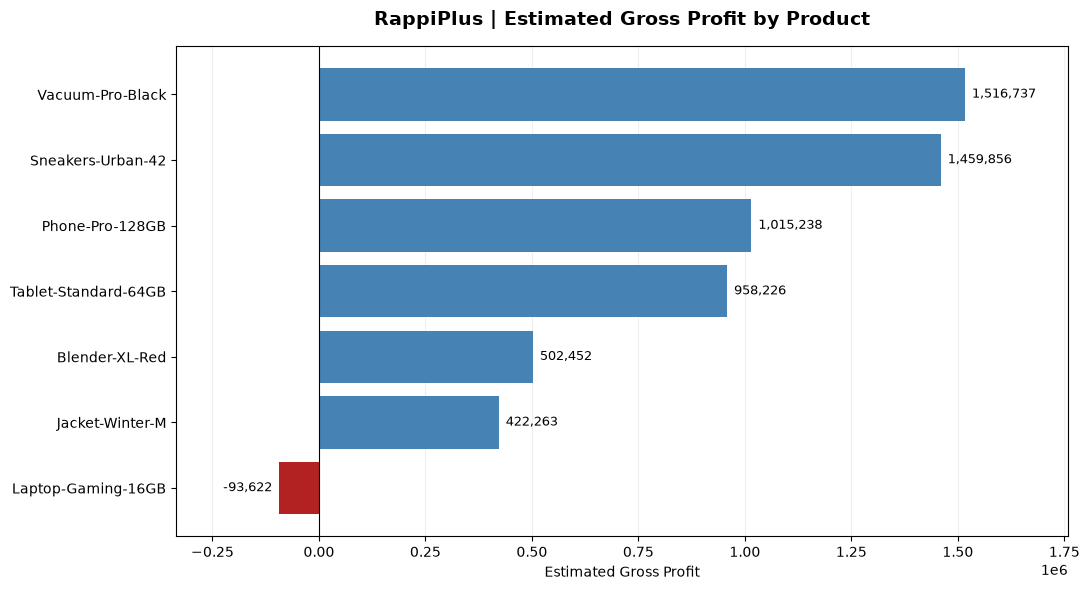

In [23]:
# Visualize estimated gross profit by product

fig, ax = plt.subplots(figsize=(11, 6))

products = product_profitability.sort_values('gross_profit')

colors = [
    'firebrick' if value < 0 else 'steelblue'
    for value in products['gross_profit']
]

bars = ax.barh(
    products['nombre_producto'],
    products['gross_profit'],
    color=colors
)

ax.bar_label(
    bars,
    labels=[
        f'{value:,.0f}'
        for value in products['gross_profit']
    ],
    padding=5,
    fontsize=9
)

ax.axvline(0, color='black', linewidth=0.8)

ax.set_title(
    'RappiPlus | Estimated Gross Profit by Product',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Estimated Gross Profit')
ax.set_ylabel('')

ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

ax.margins(x=0.15)

plt.tight_layout()
plt.show()

### Key Finding: Product Profitability

Product profitability varies significantly across the RappiPlus catalog.

- Vacuum-Pro-Black and Sneakers-Urban-42 generated the highest estimated gross profits.
- Phone-Pro-128GB, Vacuum-Pro-Black, Sneakers-Urban-42, and Tablet-Standard-64GB recorded estimated gross margins above 90%.
- Laptop-Gaming-16GB generated an estimated gross loss of 93,621.66, with a gross margin of -8.63%.

These findings suggest that revenue generation does not necessarily translate into profitability.

**Business recommendation:** Review the pricing, discount structure, and product costs of Laptop-Gaming-16GB. Validate the unusually high margins of the other products before making pricing or investment decisions.

Profitability estimates are based on available catalog costs and exclude transactions with incomplete cost information and potential returns.

## 4. Customer Behavior Analysis

### Business Question

How frequently do customers purchase from RappiPlus, and what proportion make repeat purchases?

### Methodology

Customer behavior will be evaluated using unique user identifiers and recorded orders.

Purchase frequency and repeat purchase rates will be calculated to assess customer engagement and purchasing patterns.

In [24]:
# Analyze customer purchase frequency

customer_orders = (
    orders[
        orders['tipo_transaccion'] == 'Sale'
    ]
    .groupby('id_usuario')['id_pedido']
    .nunique()
)

total_customers = len(customer_orders)

repeat_customers = (customer_orders > 1).sum()

repeat_purchase_rate = (
    repeat_customers / total_customers * 100
)

print('Total purchasing customers:', total_customers)
print('Repeat customers:', repeat_customers)
print('Repeat purchase rate (%):', round(repeat_purchase_rate, 2))
print('Average orders per customer:', round(customer_orders.mean(), 2))

Total purchasing customers: 7640
Repeat customers: 6535
Repeat purchase rate (%): 85.54
Average orders per customer: 3.26


In [25]:
# Analyze month-to-month customer repurchase

sales_orders = orders[
    orders['tipo_transaccion'] == 'Sale'
].copy()

# Get unique customers per month
monthly_customers = (
    sales_orders.groupby('mes')['id_usuario']
    .apply(set)
    .sort_index()
)

# Calculate next-month repurchase
repurchase_results = []

for i in range(len(monthly_customers) - 1):
    current_month = monthly_customers.index[i]
    next_month = monthly_customers.index[i + 1]

    current_users = monthly_customers.iloc[i]
    next_users = monthly_customers.iloc[i + 1]

    returning_users = len(current_users & next_users)

    repurchase_rate = (
        returning_users / len(current_users) * 100
    )

    repurchase_results.append({
        'month': str(current_month),
        'customers': len(current_users),
        'returned_next_month': returning_users,
        'repurchase_rate_pct': round(repurchase_rate, 2)
    })

monthly_repurchase = pd.DataFrame(repurchase_results)

monthly_repurchase

,month,customers,returned_next_month,repurchase_rate_pct
0,2025-01,3299,1229,37.25
1,2025-02,2952,1210,40.99
2,2025-03,3286,1310,39.87
3,2025-04,3263,1370,41.99
4,2025-05,3309,1296,39.17


### Key Finding: Customer Purchase Behavior

RappiPlus recorded 7,640 purchasing customers between January and June 2025.

- 85.54% of customers made more than one purchase during the analyzed period.
- Customers placed an average of 3.26 orders.
- Next-month repurchase rates ranged from 37.25% to 41.99%.
- April recorded the highest next-month repurchase rate (41.99%).

Despite high overall repeat purchasing activity, approximately 60% of customers active in a given month did not purchase again in the immediately following month.

**Business implication:** RappiPlus shows strong repeat purchasing within the semester, but opportunities remain to improve purchasing continuity between consecutive months.

These metrics describe observed customer behavior and should not be interpreted as full cohort retention.

## 5. Marketing Efficiency Analysis

### Business Question

How does marketing spending relate to recorded sales across countries and acquisition channels?

### Methodology

Marketing spending and sales will be compared using consistent date, country, and channel dimensions.

The analysis will account for differences in data coverage and exclude records with unknown geographic or acquisition channel information from segmented comparisons.

Revenue-to-spend ratios will be interpreted as descriptive indicators rather than causal attribution metrics.

In [26]:
# Prepare sales and marketing data for comparison

# Use the dates covered by marketing data
start_date = marketing['fecha'].min()
end_date = marketing['fecha'].max()

# Select identifiable sales within the marketing period
sales_marketing = orders[
    (orders['fecha_hora_pedido'].dt.normalize() >= start_date)
    & (orders['fecha_hora_pedido'].dt.normalize() <= end_date)
    & (orders['tipo_transaccion'] == 'Sale')
    & (orders['pais'] != 'Unknown')
    & (orders['fuente_referencia'] != 'Unknown')
].copy()

# Create a daily date column
sales_marketing['fecha'] = (
    sales_marketing['fecha_hora_pedido'].dt.normalize()
)

# Aggregate sales by date, country, and channel
daily_sales = (
    sales_marketing.groupby(
        ['fecha', 'pais', 'fuente_referencia'],
        as_index=False
    )
    .agg(
        orders=('id_pedido', 'nunique'),
        revenue=('monto_total', 'sum')
    )
)

# Display results
print('Sales records included:', len(sales_marketing))
print('Aggregated sales combinations:', len(daily_sales))

daily_sales.head()

Sales records included: 24485
Aggregated sales combinations: 1620


,fecha,pais,fuente_referencia,orders,revenue
0,2025-01-01,Argentina,organic,22,7499.05
1,2025-01-01,Argentina,paid_search,12,4160.15
2,2025-01-01,Argentina,social,12,3603.30
3,2025-01-01,Colombia,organic,16,6386.56
4,2025-01-01,Colombia,paid_search,23,9047.47


In [27]:
# Integrate sales and marketing spending

marketing_sales = daily_sales.merge(
    marketing[
        ['fecha', 'pais', 'canal', 'gasto']
    ],
    left_on=['fecha', 'pais', 'fuente_referencia'],
    right_on=['fecha', 'pais', 'canal'],
    how='outer',
    validate='one_to_one',
    indicator=True
)

# Validate the integration
print('Total combinations:', len(marketing_sales))

print('\nMerge results:')
print(marketing_sales['_merge'].value_counts())

print(
    '\nTotal marketing spending:',
    round(marketing_sales['gasto'].sum(), 2)
)

print(
    'Total comparable sales:',
    round(marketing_sales['revenue'].sum(), 2)
)

Total combinations: 1620

Merge results:
_merge
both          1620
left_only        0
right_only       0
Name: count, dtype: int64

Total marketing spending: 2871843.53
Total comparable sales: 9450739.67


In [28]:
# Analyze revenue and marketing spending by country and channel

marketing_performance = (
    marketing_sales.groupby(
        ['pais', 'canal'],
        as_index=False
    )
    .agg(
        orders=('orders', 'sum'),
        revenue=('revenue', 'sum'),
        marketing_spend=('gasto', 'sum')
    )
)

# Calculate descriptive revenue-to-spend ratio
marketing_performance['revenue_to_spend'] = (
    marketing_performance['revenue']
    / marketing_performance['marketing_spend']
)

# Sort by revenue-to-spend ratio
marketing_performance = marketing_performance.sort_values(
    'revenue_to_spend',
    ascending=False
)

marketing_performance.round(2)

,pais,canal,orders,revenue,marketing_spend,revenue_to_spend
1,Argentina,paid_search,2634,1044019.39,297321.98,3.51
4,Colombia,paid_search,2716,1038955.72,298901.96,3.48
5,Colombia,social,2798,1072699.33,313528.95,3.42
7,Mexico,paid_search,2757,1070779.18,326150.26,3.28
0,Argentina,organic,2702,1046133.23,319196.99,3.28
8,Mexico,social,2786,1077022.11,332113.79,3.24
3,Colombia,organic,2725,1044144.44,323222.51,3.23
6,Mexico,organic,2724,1044662.80,330231.46,3.16
2,Argentina,social,2643,1012323.47,331175.63,3.06


### Key Finding: Marketing Efficiency

Revenue-to-spend ratios ranged from 3.06 to 3.51 across the nine country-channel combinations.

- Argentina's paid_search channel recorded the highest ratio (3.51).
- Paid_search showed the highest ratio within all three countries.
- Argentina's social channel recorded the lowest ratio (3.06).

These differences suggest opportunities to investigate how marketing performance varies across countries and acquisition channels.

**Business recommendation:** Further evaluate campaign performance, customer acquisition costs, and revenue attribution before making budget allocation decisions.

Revenue-to-spend ratios are descriptive metrics and should not be interpreted as causal ROAS.

In [29]:
# Analyze correlation between marketing spending and sales

marketing_correlations = (
    marketing_sales.groupby(['pais', 'canal'])
    .apply(
        lambda group: group['gasto'].corr(group['revenue']),
        include_groups=False
    )
    .reset_index(name='pearson_correlation')
)

marketing_correlations = marketing_correlations.sort_values(
    'pearson_correlation',
    ascending=False
)

marketing_correlations.round(3)

,pais,canal,pearson_correlation
0,Argentina,organic,0.098
6,Mexico,organic,0.078
2,Argentina,social,0.037
1,Argentina,paid_search,0.017
5,Colombia,social,0.007
3,Colombia,organic,-0.028
4,Colombia,paid_search,-0.042
8,Mexico,social,-0.049
7,Mexico,paid_search,-0.069


### Key Finding: Marketing Spend and Sales Correlation

Daily marketing spending showed negligible linear correlations with recorded daily sales across all nine country-channel segments.

Pearson correlation coefficients ranged from -0.069 to +0.098.

Although some segments recorded higher revenue-to-spend ratios, these results did not translate into meaningful contemporaneous linear correlations between spending and sales.

**Business implication:** Marketing efficiency cannot be reliably assessed using revenue-to-spend ratios or same-day correlations alone.

Further evaluation of attribution, campaign performance, and potential delayed effects is recommended before making budget allocation decisions.

Correlation does not establish causation, and these findings do not demonstrate that marketing investment is ineffective.

## 6. Executive Summary

### Business Performance Overview

This analysis evaluated RappiPlus's commercial performance from January to June 2025, focusing on revenue trends, product profitability, customer purchasing behavior, and marketing efficiency.

### Key Findings

**1. Revenue Performance**

* Monthly sales fluctuated throughout the analyzed period, with no sustained upward trend.
* Identified sales decreased by **2.46% between January and June**.
* February recorded the largest monthly decline (-12.91%), followed by the strongest recovery in March (+14.94%).

**2. Product Profitability**

* Vacuum-Pro-Black and Sneakers-Urban-42 generated the highest estimated gross profits.
* Laptop-Gaming-16GB recorded an estimated gross loss of **93,621.66**, with a gross margin of **-8.63%**.
* Four products recorded estimated gross margins above 90%, highlighting the importance of validating product cost assumptions.

**3. Customer Purchasing Behavior**

* RappiPlus recorded **7,640 purchasing customers** during the analyzed period.
* **85.54%** made more than one purchase, averaging **3.26 orders per customer**.
* Next-month repurchase rates ranged from **37.25% to 41.99%**, indicating that repeat purchases within the semester did not always translate into consecutive-month purchasing activity.

**4. Marketing Efficiency**

* Argentina's paid_search channel recorded the highest descriptive revenue-to-spend ratio (**3.51**).
* Paid_search showed the highest revenue-to-spend ratio within all three countries.
* Daily marketing spending and recorded sales showed negligible linear correlations across the nine country-channel segments (Pearson coefficients between **-0.069 and +0.098**).
* These results do not establish the causal impact of marketing spending on sales.

### Business Recommendations

**1. Investigate Product Profitability**

Review the pricing, discounts, and cost structure of Laptop-Gaming-16GB. Validate unusually high product margins before making commercial decisions.

**2. Strengthen Customer Repurchase**

Investigate opportunities to improve purchasing continuity between consecutive months through customer segmentation and targeted retention initiatives.

**3. Improve Marketing Measurement**

Strengthen campaign attribution and evaluate customer acquisition costs before reallocating marketing budgets. Consider potential delayed relationships between spending and sales.

**4. Monitor Commercial Growth**

Track revenue, purchasing frequency, and product profitability over time to identify the drivers of sales fluctuations and evaluate opportunities for sustainable growth.

### Analytical Limitations

* Ten extreme-quantity transactions were excluded from the main analytical dataset and preserved separately.
* Product profitability estimates exclude transactions with incomplete cost information and potential returns.
* Gross profit estimates do not include marketing expenses or other operating costs.
* Marketing comparisons cover January 1 through June 29, 2025, due to differences in data availability.
* Revenue-to-spend ratios and Pearson correlations are descriptive measures and do not establish marketing attribution or causality.
* Customer repurchase metrics describe behavior within the observed period and should not be interpreted as full cohort retention.

### Conclusion

RappiPlus demonstrates substantial repeat purchasing activity and positive estimated gross profit across most products. However, the business did not establish sustained monthly sales growth during the analyzed period.

The analysis identified a product with negative estimated gross profitability, opportunities to improve purchasing continuity, and limitations in evaluating marketing effectiveness.

These findings provide a foundation for further investigation and data-driven commercial decisions.

Additional SQL-based funnel and cohort analyses, together with A/B experiment evaluation, will complement these findings.
